# Step 4: A neural network and an untuned LLM (Week 6 Day 4)

**Course:** Week 6 Day 4 of the LLM Engineering course: from traditional ML to neural networks to LLMs. Everything here runs on our own products, not the course's.

## The question

Part 3 set the bar: logistic regression on a 2,000-word bag of words gets **49.8%** of 141 categories right. This notebook asks two things:

- **A. A vanilla neural network.** Same words in, same 141 categories out, with layers in between. What does training actually do to it, and does it beat 49.8%?
- **B. An LLM with no tuning.** gpt-4.1-nano reads each product and picks one of the 141 categories. This is the "before" number: Day 5 fine-tunes the same model and tests it on the same products.

The network copies the course's 8-layer design, changed only where classification needs it. The features are Part 3's, so the only difference from 49.8% is the model.

## Step 1: Load our products and turn categories into numbers

**Why:** a neural network can only output numbers. For a price that's one number. For 141 categories it's 141 numbers, one score per category, so each training label has to become a category id (0 to 140) instead of a name. We also need PyTorch, which Part 3 didn't use.

**What the code does:**

1. Installs PyTorch (run once).
2. Loads the same three splits as Part 3 from Hugging Face.
3. Turns each category name into an id with `LabelEncoder`, fitted on training labels only.
4. Prints one product exactly as the network will receive it, and the id it has to learn.

In [1]:
# Run once: PyTorch, the neural network library the course uses.
# If Cell 1 can't import torch right after this installs, restart the kernel.
%pip install --user -q torch

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 1: our products, categories as ids, and PyTorch ready
import time                        # to time training
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt    # training curves and the final chart
from tqdm.auto import tqdm         # progress bars
import torch
from sklearn.preprocessing import LabelEncoder

REPO = "raghu619/shopify_category_lite"   # our dataset: raw text, Part 2's summary, and the label

# 1) The same three splits as Part 3
splits = {}
for s in tqdm(["train", "validation", "test"], desc="Loading splits from Hugging Face", unit="split"):
    splits[s] = pd.read_parquet(f"hf://datasets/{REPO}/data/{s}.parquet")
train, val, test = splits["train"], splits["validation"], splits["test"]
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,} | {train['label'].nunique()} categories")

# 2) Category names -> ids 0..140, fitted on training labels only
encoder = LabelEncoder().fit(train["label"])
y_train, y_val, y_test = (encoder.transform(df["label"]) for df in (train, val, test))
N_CLASSES = len(encoder.classes_)
print(f"{N_CLASSES} categories -> ids 0 to {N_CLASSES - 1} (alphabetical): "
      f"0 = {encoder.classes_[0]!r}, {N_CLASSES - 1} = {encoder.classes_[-1]!r}")

# 3) PyTorch, and fixed seeds so every run starts from the same random weights
torch.manual_seed(42)
np.random.seed(42)
print(f"PyTorch {torch.__version__} | Apple GPU (MPS) available: {torch.backends.mps.is_available()} "
      f"(we train on CPU: this network is small)")

# 4) One product, exactly as the network will receive it, and the answer it must learn
row = train.iloc[5]
print(f"\nINPUT (summary):\n{row['summary']}")
print(f"\nANSWER: {row['label']!r} -> id {encoder.transform([row['label']])[0]}")

Loading splits from Hugging Face:   0%|          | 0/3 [00:00<?, ?split/s]

/Users/raghvendaraokoduri/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


train 20,027 | validation 2,498 | test 2,497 | 141 categories
141 categories -> ids 0 to 140 (alphabetical): 0 = 'Animals & Pet Supplies > Pet Supplies', 140 = 'Vehicles & Parts > Vehicles'
PyTorch 2.8.0 | Apple GPU (MPS) available: True (we train on CPU: this network is small)

INPUT (summary):
Title: League of Legends Agony's Embrace Evelynn K/DA Skin Cosplay Shoes Lilac
Brand: Unknown
Description: Cosplay shoes inspired by Evelynn's Agony's Embrace K/DA skin from League of Legends.
Details: Made of artificial leather, purple color, processing time 5-7 days.

ANSWER: 'Apparel & Accessories > Costumes & Accessories' -> id 3


### Step 1 findings

- Same splits as Parts 1 and 3: 20,027 / 2,498 / 2,497 products across 141 categories. Every validation and test category also appears in training (the encoder would have raised an error otherwise).
- Ids are alphabetical: 0 = Animals & Pet Supplies > Pet Supplies, 140 = Vehicles & Parts > Vehicles. They're names, not quantities, so the network gets 141 outputs instead of one.
- PyTorch 2.8.0. The Apple GPU (MPS) is available, but this network is small enough to train on the CPU.
- The example is a pair of League of Legends cosplay shoes, labelled **Apparel & Accessories > Costumes & Accessories** (id 3). Is a cosplay shoe a shoe or a costume? The dataset says costume. A trained model learns conventions like this from examples; an untuned LLM has to guess them. Worth remembering for Part B.

## Step 2: Turn words into numbers

**Why:** the network's first layer multiplies numbers by weights, so every product has to become a fixed-length row of numbers. We reuse Part 3's bag of words exactly: the 2,000 most frequent words in training summaries (English stop words removed), counted per product. Same features as the 49.8% logistic regression, so any difference later comes from the model alone.

PyTorch then needs two more things:

- **Tensors**, PyTorch's arrays: product counts become a float tensor (20,027 × 2,000, about 160 MB) and category ids an integer tensor.
- **Batches:** the network learns from 64 products at a time, reshuffled on every pass through the data, as in the course. A `DataLoader` does the batching and shuffling.

**What the code does:**

1. Learns the vocabulary from training summaries only, then counts the same 2,000 words in validation and test.
2. Prints the vocabulary words that light up for the Step 1 product: that list is everything the network will ever see of it.
3. Converts features and labels to tensors.
4. Builds a seeded `DataLoader`, so every training run sees the same shuffles no matter which cells ran before.

In [3]:
# Cell 2: words -> numbers (Part 3's bag of words), then PyTorch tensors and batches
from sklearn.feature_extraction.text import CountVectorizer
from torch.utils.data import TensorDataset, DataLoader

# 1) Exactly Part 3's features: the 2,000 most frequent words in training summaries
vectorizer = CountVectorizer(max_features=2000, stop_words="english")
X_train = vectorizer.fit_transform(tqdm(train["summary"], desc="Learning the vocabulary (train only)", unit="product"))
X_val = vectorizer.transform(val["summary"])      # count the SAME 2,000 words
X_test = vectorizer.transform(test["summary"])
vocab = vectorizer.get_feature_names_out()
print(f"Each product is now a row of {X_train.shape[1]:,} numbers. "
      f"On average {X_train.nnz / X_train.shape[0]:.0f} of them are non-zero; the rest are 0.")

# 2) Everything the network will ever see of the Step 1 product
x5 = X_train[5]
words = sorted(zip(vocab[x5.indices], x5.data), key=lambda wc: -wc[1])
print(f"\nThe Step 1 product lights up {x5.nnz} of {len(vocab):,} inputs:")
print("   " + ", ".join(f"{w} x{c}" if c > 1 else w for w, c in words))

# 3) PyTorch tensors: float features, integer category ids (the classification loss wants ids, not names)
X_train_t = torch.from_numpy(X_train.astype(np.float32).toarray())
X_val_t = torch.from_numpy(X_val.astype(np.float32).toarray())
X_test_t = torch.from_numpy(X_test.astype(np.float32).toarray())
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)
print(f"\nTensors: X_train {tuple(X_train_t.shape)} float32 "
      f"({X_train_t.element_size() * X_train_t.nelement() / 1e6:.0f} MB) | y_train {tuple(y_train_t.shape)} int64")

# 4) Batches of 64 products, reshuffled every pass (as in the course).
#    make_loader() builds a fresh, seeded loader, so every training run sees the same shuffles,
#    no matter which cells ran before (Part 3's lesson: notebooks hide state).
def make_loader(seed=42, batch_size=64):
    return DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

batch_X, batch_y = next(iter(make_loader()))
print(f"One batch: inputs {tuple(batch_X.shape)}, answers {tuple(batch_y.shape)} | "
      f"{len(make_loader())} batches = one pass (epoch) over the training set")

Learning the vocabulary (train only):   0%|          | 0/20027 [00:00<?, ?product/s]

Each product is now a row of 2,000 numbers. On average 19 of them are non-zero; the rest are 0.

The Step 1 product lights up 15 of 2,000 inputs:
   skin x2, shoes x2, title, brand, unknown, description, details, color, inspired, artificial, leather, purple, processing, time, days

Tensors: X_train (20027, 2000) float32 (160 MB) | y_train (20027,) int64
One batch: inputs (64, 2000), answers (64,) | 313 batches = one pass (epoch) over the training set


### Step 2 findings

- Each product is now 2,000 numbers, about 19 of them non-zero on average. The training set is a 20,027 × 2,000 tensor (160 MB), served in 313 batches of 64 per pass.
- The cosplay shoes light up 15 inputs, and the most telling word isn't one of them: **"cosplay" didn't make the 2,000-word vocabulary**, and neither did "League" or "Legends".
- 4 of the 15 (title, brand, description, details) are format words every product has, so they can't separate categories. "Unknown" (from Brand: Unknown) and the shipping words (processing, time, days) carry little signal.
- What's left: shoes, leather, artificial, purple, color, inspired, and **skin x2**. Here "skin" means a video-game skin; in a store it usually means skincare.
- So the network will judge this product on words like "shoes", "leather" and "skin", and probably won't guess "costume". The LLM in Part B reads the whole summary, including "Cosplay" and "League of Legends".

## Step 3: Build the network

**Why:** this is the course's vanilla network, the same 8 layers it used for price. Each layer does one thing: multiply its inputs by a grid of weights, add a bias, and pass the result through ReLU (negative numbers become 0). The only change for classification is the last layer: **64 → 141 scores instead of 64 → 1 price**.

Two ideas to have in mind before training:

- **Why ReLU matters:** without it, 8 linear layers multiply out to a single linear layer, which is logistic regression again. The bend that ReLU adds between layers is what lets the network combine words ("purple" means something different next to "shoes" than next to "paint").
- **Logits and softmax:** the network outputs 141 raw scores (logits). Softmax turns them into probabilities that sum to 1: the higher the score, the bigger the share.

**What the code does:**

1. Defines the course's network with 141 outputs and creates it from a fixed seed.
2. Counts the parameters layer by layer and compares the total with logistic regression.
3. Runs the untrained network on the cosplay shoes. Before any training, every category should get about 1/141 = 0.7%.

In [4]:
# Cell 3: the course's 8-layer network, with 141 outputs instead of 1
import torch.nn as nn

class NeuralNetwork(nn.Module):
    """The course's vanilla network from Day 4. Only change: the last layer outputs 141 category scores, not 1 price."""
    def __init__(self, input_size, n_classes):
        super().__init__()
        self.layer1 = nn.Linear(input_size, 128)
        self.layer2 = nn.Linear(128, 64)
        self.layer3 = nn.Linear(64, 64)
        self.layer4 = nn.Linear(64, 64)
        self.layer5 = nn.Linear(64, 64)
        self.layer6 = nn.Linear(64, 64)
        self.layer7 = nn.Linear(64, 64)
        self.layer8 = nn.Linear(64, n_classes)   # course: nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.relu(self.layer3(x))
        x = self.relu(self.layer4(x))
        x = self.relu(self.layer5(x))
        x = self.relu(self.layer6(x))
        x = self.relu(self.layer7(x))
        return self.layer8(x)                    # 141 raw scores ("logits"); no ReLU on the output

torch.manual_seed(42)                            # same starting weights every time this cell runs
model = NeuralNetwork(X_train_t.shape[1], N_CLASSES)

# 1) Where the parameters live
print("layer      in -> out     parameters")
total = 0
for name, layer in model.named_children():
    if isinstance(layer, nn.Linear):
        n = sum(p.numel() for p in layer.parameters())   # weights (in x out) + one bias per output
        total += n
        print(f"{name:9s} {layer.in_features:>5,} -> {layer.out_features:<5,} {n:>10,}")
lr_params = X_train_t.shape[1] * N_CLASSES + N_CLASSES
print(f"{'total':9s} {'':14s} {total:>10,}")
print(f"logistic regression: {X_train_t.shape[1]:,} x {N_CLASSES} + {N_CLASSES} = {lr_params:,}")

# 2) The untrained network looks at the cosplay shoes
model.eval()
with torch.no_grad():
    logits = model(X_train_t[5:6])[0]            # 141 raw scores for one product
    probs = torch.softmax(logits, dim=0)         # softmax: scores -> probabilities that sum to 1
print(f"\nUntrained network on the cosplay shoes: 141 scores between {logits.min():.3f} and {logits.max():.3f}")
top = torch.topk(probs, 3)
print("Top 3 categories:")
for p, i in zip(top.values, top.indices):
    print(f"   {p:.2%}  {encoder.classes_[int(i)]}")
true_id = int(y_train[5])
print(f"Correct category ({encoder.classes_[true_id]}): {probs[true_id]:.2%} | "
      f"a uniform guess gives 1/{N_CLASSES} = {1 / N_CLASSES:.2%}")

layer      in -> out     parameters
layer1    2,000 -> 128      256,128
layer2      128 -> 64         8,256
layer3       64 -> 64         4,160
layer4       64 -> 64         4,160
layer5       64 -> 64         4,160
layer6       64 -> 64         4,160
layer7       64 -> 64         4,160
layer8       64 -> 141        9,165
total                       294,349
logistic regression: 2,000 x 141 + 141 = 282,141

Untrained network on the cosplay shoes: 141 scores between -0.173 and 0.174
Top 3 categories:
   0.84%  Electronics > Computers
   0.84%  Business & Industrial > Hairdressing & Cosmetology
   0.83%  Services > Personal Services
Correct category (Apparel & Accessories > Costumes & Accessories): 0.63% | a uniform guess gives 1/141 = 0.71%


### Step 3 findings

- **294,349 parameters**, about the same budget as logistic regression's 282,141, in a very different shape: **256,128 (87%) sit in layer 1**, which squeezes 2,000 word counts into 128 numbers. Layers 2 to 7 hold only 29,056 between them, and layer 8 holds 9,165.
- Logistic regression gives every word a direct vote for every category. This network lets words reach the 141 categories only through a 64-number bottleneck.
- Untrained, the network has no opinion: its 141 scores sit between -0.17 and 0.17, so softmax spreads the probability almost evenly (0.84% at the top against 0.71% for a uniform guess).
- The correct category got 0.63%, slightly below uniform: random weights, random luck.

## Step 4: One training step by hand

**Why:** training is 4 lines repeated thousands of times. Running them once, slowly, shows what each one does.

1. **Forward:** the network produces 141 scores for each of 64 products.
2. **Loss:** cross-entropy. For each product, take the probability given to the correct category and compute -ln(p). Confident and right gives nearly 0, a uniform guess gives ln(141) = 4.95, and confident and wrong gives a large number. The loss is the average over the 64 products.
3. **Backward:** for every one of the 294,349 parameters, PyTorch computes the gradient: in which direction, and how strongly, a small change would lower the loss.
4. **Step:** the optimizer (Adam, learning rate 0.001, as in the course) nudges every parameter against its gradient.

Two PyTorch details that are classic interview questions:

- `CrossEntropyLoss` takes the raw scores, not probabilities. It applies softmax inside, in a numerically safe way. Applying softmax yourself first is a common bug.
- `zero_grad()` comes first because PyTorch **adds** new gradients to the old ones. Forget it, and every step uses the sum of all previous gradients.

**What the code does:** runs the 4 stages once on the first batch, then prints the loss before the step, the gradient size in each layer, how many parameters moved and by how much, and the loss on the same batch after the step.

This step changes the model's weights. Step 5 starts again from fresh ones.

In [5]:
# Cell 4: one training step by hand (forward, loss, backward, step) on one batch of 64 products
import math
import torch.optim as optim

loss_function = nn.CrossEntropyLoss()                  # raw scores + correct ids in; softmax and -ln(p) inside
optimizer = optim.Adam(model.parameters(), lr=0.001)   # same optimizer and learning rate as the course

batch_X, batch_y = next(iter(make_loader()))           # the same first batch every time (seeded loader)
before = {name: p.detach().clone() for name, p in model.named_parameters()}   # snapshot, to see what changes
model.train()

# The 4 lines of training (plus zero_grad, which clears the previous step's gradients)
optimizer.zero_grad()
logits = model(batch_X)                     # 1) forward: 141 scores for each of the 64 products
loss = loss_function(logits, batch_y)       # 2) loss: average of -ln(probability of the correct category)
loss.backward()                             # 3) backward: a gradient for every parameter
optimizer.step()                            # 4) step: Adam nudges every parameter against its gradient

print(f"Loss before the step: {loss.item():.4f} | uniform guess: ln({N_CLASSES}) = {math.log(N_CLASSES):.4f}")

# How strongly was each layer told to change?
print("\nGradient per layer (weights only):")
print("   layer      average |gradient|   weights with any gradient")
for name, p in model.named_parameters():
    if name.endswith("weight"):
        g = p.grad
        print(f"   {name.split('.')[0]:9s}  {g.abs().mean().item():>18.7f}   {(g != 0).float().mean().item():>10.0%}")

# What did the step actually change?
moves = torch.cat([(p.detach() - before[name]).flatten() for name, p in model.named_parameters()])
moved = moves[moves != 0]
print(f"\nParameters that moved: {moved.numel():,} of {moves.numel():,} ({moved.numel() / moves.numel():.0%}) | "
      f"typical move: {moved.abs().median().item():.5f}")

# Same batch again: did one step lower the loss?
with torch.no_grad():
    loss_after = loss_function(model(batch_X), batch_y).item()
print(f"Loss on the same batch after one step: {loss_after:.4f} ({loss_after - loss.item():+.4f})")

Loss before the step: 4.9465 | uniform guess: ln(141) = 4.9488

Gradient per layer (weights only):
   layer      average |gradient|   weights with any gradient
   layer1              0.0000009          17%
   layer2              0.0000026          77%
   layer3              0.0000034          48%
   layer4              0.0000086          34%
   layer5              0.0000238          32%
   layer6              0.0000673          28%
   layer7              0.0001017          27%
   layer8              0.0002947          52%

Parameters that moved: 62,066 of 294,349 (21%) | typical move: 0.00100
Loss on the same batch after one step: 4.9411 (-0.0054)


### Step 4 findings

- **Loss before: 4.9465**, almost exactly ln(141) = 4.9488. The untrained network is a uniform guesser, which is the right starting point.
- **Vanishing gradients:** the error signal starts at the output and shrinks on its way back, from 0.00029 in layer 8 to 0.0000009 in layer 1, about **340× weaker**. Each layer multiplies it by small weights, and ReLU blocks it wherever a unit was off. Layer 1 holds 87% of the parameters (the word weights) and gets the weakest signal.
- **Most weights got no gradient at all.** In layer 1 only 17% did: a word that none of these 64 products contain passes nothing back. Deeper layers drop from 77% to 27%: units that output 0 for the whole batch pass nothing back either. In total 62,066 of 294,349 parameters (21%) moved.
- **Every parameter that moved, moved by 0.00100: exactly the learning rate.** Adam divides each gradient by its own typical size, so on the first step every move is ±0.001, whether the gradient was 0.0003 or 0.0000009. Plain gradient descent would have moved layer 1 about 340× less than layer 8. Adam is what lets a plain 8-layer network train at all. The structural fix is in the course's optional "redemption" network: residual (skip) connections and LayerNorm, which give the gradient a shortcut back to the early layers.
- One step lowered the loss on that batch by 0.0054 (4.9465 → 4.9411). Training is about 3,130 of these steps (313 batches × 10 passes).

## Step 5: Train for 10 passes and watch it learn, then memorise

**Why:** one step barely moved the loss. Training repeats it: 313 batches make one pass (an epoch) over all 20,027 products, and we make 10 passes, about 3,130 steps. The course stopped at 2 passes; 10 lets us see what happens after the network has learned what it can.

After every pass we measure loss and accuracy on two sets:

- **Training products**, the ones it learns from. These numbers keep improving almost no matter what, because the network can memorise them.
- **Validation products**, 2,498 it never trains on. These show whether it learned something that carries over to new products.

When training keeps improving but validation stops, or gets worse, the network has started memorising. So we keep the weights from the epoch with the best validation accuracy, not the last one. The test set stays untouched until Step 6.

**What the code does:**

1. `build_model()` creates a fresh network from the same seed, so Step 4's practice step doesn't leak in.
2. `train_model()` runs the 4 lines over every batch, 10 times, with a progress bar, and prints training and validation loss and accuracy after each pass.
3. Keeps a copy of the best weights on validation and restores them at the end.
4. Plots both curves and saves the chart to `assets/part4_training_curves.png`.

8-layer network:


8-layer network: epoch 1/10:   0%|          | 0/313 [00:00<?, ?batch/s]

   epoch  1 | training: loss 4.355, accuracy   2.3% | validation: loss 4.401, accuracy   2.6%


8-layer network: epoch 2/10:   0%|          | 0/313 [00:00<?, ?batch/s]

   epoch  2 | training: loss 4.084, accuracy   4.6% | validation: loss 4.183, accuracy   4.2%


...

   epoch  8 | training: loss 1.972, accuracy  44.4% | validation: loss 4.803, accuracy  20.1%


8-layer network: epoch 9/10:   0%|          | 0/313 [00:00<?, ?batch/s]

   epoch  9 | training: loss 1.788, accuracy  48.6% | validation: loss 4.989, accuracy  21.0%


8-layer network: epoch 10/10:   0%|          | 0/313 [00:00<?, ?batch/s]

   epoch 10 | training: loss 1.484, accuracy  56.8% | validation: loss 5.897, accuracy  22.5%
   kept epoch 10: best validation accuracy 22.5%
Trained in 4s


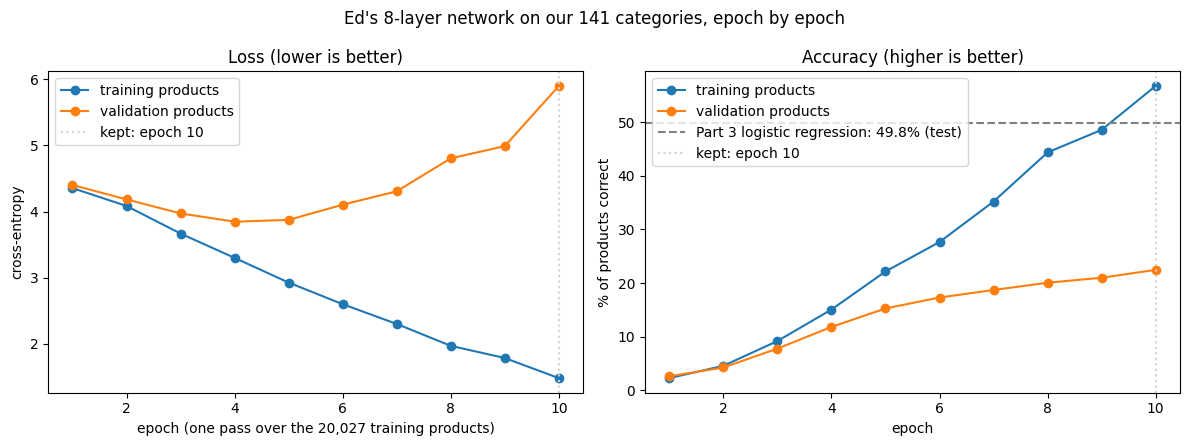

In [6]:
# Cell 5: train the course's network for 10 passes (epochs), checking training vs validation after each one
EPOCHS = 10

def build_model():
    """A fresh network from the same seed, so every experiment starts from identical weights."""
    torch.manual_seed(42)
    return NeuralNetwork(X_train_t.shape[1], N_CLASSES)

def measure(model, X, y):
    """Average loss and accuracy over a whole split, without training."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        return loss_function(logits, y).item(), (logits.argmax(dim=1) == y).float().mean().item()

def train_model(model, epochs=EPOCHS, name="network", print_every=1):
    """The course's training loop, plus a validation check after every pass. Restores the best weights on validation."""
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history, best = [], {"val_acc": -1.0}
    print(f"{name}:")
    for epoch in range(1, epochs + 1):
        model.train()
        for batch_X, batch_y in tqdm(make_loader(seed=epoch), desc=f"{name}: epoch {epoch}/{epochs}",
                                     unit="batch", leave=False):
            optimizer.zero_grad()
            loss = loss_function(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()
        train_loss, train_acc = measure(model, X_train_t, y_train_t)
        val_loss, val_acc = measure(model, X_val_t, y_val_t)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_acc": train_acc, "val_acc": val_acc})
        if val_acc > best["val_acc"]:
            best = {"val_acc": val_acc, "epoch": epoch,
                    "weights": {k: v.clone() for k, v in model.state_dict().items()}}
        if epoch % print_every == 0 or epoch == epochs:
            print(f"   epoch {epoch:2d} | training: loss {train_loss:.3f}, accuracy {train_acc:6.1%} | "
                  f"validation: loss {val_loss:.3f}, accuracy {val_acc:6.1%}")
    model.load_state_dict(best["weights"])     # keep the best epoch on validation, not the last one
    print(f"   kept epoch {best['epoch']}: best validation accuracy {best['val_acc']:.1%}")
    return pd.DataFrame(history), best["epoch"]

model = build_model()
start = time.time()
history, best_epoch = train_model(model, name="8-layer network")
nn_seconds = time.time() - start
print(f"Trained in {nn_seconds:.0f}s")

# Training vs validation, epoch by epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(history["epoch"], history["train_loss"], "o-", label="training products")
ax1.plot(history["epoch"], history["val_loss"], "o-", label="validation products")
ax1.set(title="Loss (lower is better)", xlabel="epoch (one pass over the 20,027 training products)",
        ylabel="cross-entropy")
ax2.plot(history["epoch"], history["train_acc"] * 100, "o-", label="training products")
ax2.plot(history["epoch"], history["val_acc"] * 100, "o-", label="validation products")
ax2.axhline(49.8, color="gray", linestyle="--", label="Part 3 logistic regression: 49.8% (test)")
ax2.set(title="Accuracy (higher is better)", xlabel="epoch", ylabel="% of products correct")
for ax in (ax1, ax2):
    ax.axvline(best_epoch, color="lightgray", linestyle=":", label=f"kept: epoch {best_epoch}")
    ax.legend()
fig.suptitle("The course's 8-layer network on our 141 categories, epoch by epoch")
plt.tight_layout()
plt.savefig("assets/part4_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 5 findings

- **The course's network reached only 22.5% on validation** after 10 passes, less than half of logistic regression's 49.8%. It trained in 3 seconds, so time isn't the issue.
- **A very slow start:** after one full pass (313 steps) it got 2.6% right, barely above "most common category" (2.0%). That's Step 4's vanishing gradient at full scale: layer 1 holds the word weights and gets the weakest error signal.
- **Memorising starts around epoch 4.** Validation loss bottoms out at 3.85 there and climbs to 5.90 by epoch 10, while training loss keeps falling (4.36 → 1.48). By epoch 10 the network gets 56.8% of training products right but only 22.5% of new ones.
- **Loss and accuracy disagree after epoch 4:** validation loss gets worse while validation accuracy keeps improving (11.8% → 22.5%). Accuracy only checks the top guess. Loss also scores the probability given to the correct category, and -ln(p) explodes when that probability is near 0, which is what a confident wrong guess does. So the network gets more new products right but is more confidently wrong on the rest. That's overconfidence, the other face of memorising.
- **Which epoch you keep depends on what you measure.** By validation loss we'd keep epoch 4 (11.8% accuracy); by validation accuracy, epoch 10 (22.5%). Accuracy was still rising at epoch 10, so 22.5% isn't this network's ceiling.

## Step 6: The control experiment, no hidden layers

**Why:** 22.5% raises a question. Is the training loop broken, or is the architecture the problem? A control answers it. We train a network with **no hidden layers**: one linear layer from the 2,000 words straight to the 141 scores. With softmax and cross-entropy on top, that is exactly logistic regression, written in PyTorch. Same words, same loop, same optimizer and learning rate; only the architecture differs.

10 passes took 3 seconds, so both networks now get **50 passes** and keep their best epoch on validation. Each gets its best shot.

How to read the result:

- If no hidden layers lands near 49.8%, the loop is fine and the 8 layers are the problem.
- If it struggles too, the problem is in the loop or the data, not the depth.

**What the code does:**

1. Trains the course's 8-layer network again for 50 passes, printing every 10th.
2. Trains the no-hidden-layer network the same way.
3. Prints each one's best validation accuracy, the epoch it came from, and its parameter count.
4. Plots validation accuracy per epoch for both and saves it to `assets/part4_depth_vs_none.png`.

Cell 5 gained a `print_every` option, so re-run Cell 5 before this one (3 seconds; the fixed seeds should give the same numbers).

8-layer network:


8-layer network: epoch 1/50:   0%|          | 0/313 [00:00<?, ?batch/s]

8-layer network: epoch 2/50:   0%|          | 0/313 [00:00<?, ?batch/s]

8-layer network: epoch 3/50:   0%|          | 0/313 [00:00<?, ?batch/s]

8-layer network: epoch 4/50:   0%|          | 0/313 [00:00<?, ?batch/s]

...

no hidden layers: epoch 47/50:   0%|          | 0/313 [00:00<?, ?batch/s]

no hidden layers: epoch 48/50:   0%|          | 0/313 [00:00<?, ?batch/s]

no hidden layers: epoch 49/50:   0%|          | 0/313 [00:00<?, ?batch/s]

no hidden layers: epoch 50/50:   0%|          | 0/313 [00:00<?, ?batch/s]

   epoch 50 | training: loss 0.178, accuracy  97.3% | validation: loss 3.046, accuracy  47.8%
   kept epoch 7: best validation accuracy 51.8%

8-layer network  | 294,349 parameters | best validation accuracy 27.5% at epoch 47 (training 95.8%) | 50 passes in 19s
no hidden layers | 282,141 parameters | best validation accuracy 51.8% at epoch 7 (training 82.1%) | 50 passes in 9s


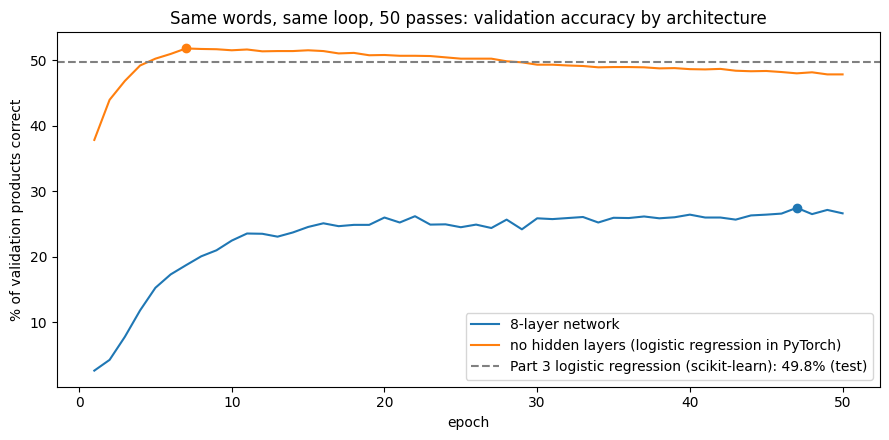

In [7]:
# Cell 6: the control experiment. Same words, same loop, 50 passes each; only the architecture differs.
LONG_EPOCHS = 50

# A) The course's 8-layer network again, now with 50 passes to find its peak
net8 = build_model()
start = time.time()
hist8, best8 = train_model(net8, epochs=LONG_EPOCHS, name="8-layer network", print_every=10)
secs8 = time.time() - start

# B) No hidden layers: one Linear layer from 2,000 words straight to 141 scores = logistic regression in PyTorch
torch.manual_seed(42)
net0 = nn.Linear(X_train_t.shape[1], N_CLASSES)
start = time.time()
hist0, best0 = train_model(net0, epochs=LONG_EPOCHS, name="no hidden layers", print_every=10)
secs0 = time.time() - start

# Side by side
print()
for name, hist, best, secs, net in [("8-layer network", hist8, best8, secs8, net8),
                                    ("no hidden layers", hist0, best0, secs0, net0)]:
    row = hist.iloc[best - 1]
    n_params = sum(p.numel() for p in net.parameters())
    print(f"{name:16s} | {n_params:,} parameters | best validation accuracy {row['val_acc']:.1%} at epoch {best} "
          f"(training {row['train_acc']:.1%}) | 50 passes in {secs:.0f}s")

# Validation accuracy per epoch, both architectures
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, hist, best in [("8-layer network", hist8, best8),
                         ("no hidden layers (logistic regression in PyTorch)", hist0, best0)]:
    line, = ax.plot(hist["epoch"], hist["val_acc"] * 100, "-", label=name)
    ax.plot(best, hist["val_acc"].iloc[best - 1] * 100, "o", color=line.get_color())   # the kept epoch
ax.axhline(49.8, color="gray", linestyle="--", label="Part 3 logistic regression (scikit-learn): 49.8% (test)")
ax.set(title="Same words, same loop, 50 passes: validation accuracy by architecture",
       xlabel="epoch", ylabel="% of validation products correct")
ax.legend()
plt.tight_layout()
plt.savefig("assets/part4_depth_vs_none.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 6 findings

| | No hidden layers | 8-layer network |
|---|---|---|
| Parameters | 282,141 | 294,349 |
| Validation accuracy after 1 pass | about 38% | 2.6% |
| Best validation accuracy | **51.8%** (epoch 7) | **27.5%** (epoch 47) |
| Training accuracy at that epoch | 82.1% | 95.8% |
| 50 passes took | 10s | 16s |

- **The loop is fine.** Same words, same loop, same optimizer: with no hidden layers the network reaches 51.8% on validation, in line with Part 3's 49.8%. Step 5's 22.5% wasn't a bug.
- **Depth is the problem here.** Given 50 passes, the course's 8-layer network plateaus around 26 to 27% and peaks at 27.5%. It memorises almost every training product (95.8%) while learning little that carries over to new ones.
- **Both models memorise; they learn different things on the way.** The no-hidden network gives every word a direct vote for every category, and those votes carry over to new products. The 8-layer network squeezes the words through 128 and then 64 numbers and learns combinations that identify individual training products. With about 142 products per category, there isn't enough data for 8 layers to find combinations that generalise.
- **Overconfidence at its extreme:** the 8-layer network's validation loss reached 15.5 by epoch 50. When it's wrong, the correct category gets essentially zero probability.
- **No hidden layers overfits too, just more slowly:** it peaks at epoch 7 (51.8%) and drifts down to 47.8% by epoch 50. scikit-learn's LogisticRegression has a built-in brake (L2 regularisation, which keeps the weights small). Our PyTorch version has none, so keeping the best epoch on validation (early stopping) is its brake.

## Step 7: The honest numbers, on the test set

**Why:** the validation numbers above are each model's best of 50 checks, so they're a little optimistic: picking the highest of 50 noisy measurements favours a lucky epoch. The test set hasn't been used for any choice. Each model's kept weights are scored on the 2,497 test products exactly once, with Part 3's metrics (accuracy and macro-F1).

We also refit Part 3's scikit-learn logistic regression on these same features. It should reproduce **49.8%** exactly, which proves this notebook's features match Part 3's and the comparison is fair.

**What the code does:**

1. Defines `score()` as in Part 3, plus a `results` list that the final chart will use after Part B.
2. Refits scikit-learn's logistic regression (about 5 seconds) and scores it.
3. Scores both PyTorch networks with the weights they kept.
4. Compares each network's validation accuracy with its test accuracy.

In [8]:
# Cell 7: the honest numbers. Every model scored once on the 2,497 test products.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

results = []   # one row per model; the final chart (after Part B) is built from this

def score(model_name, y_pred, seconds=None):
    """Score one model's test predictions with Part 3's metrics, print one line, keep the row."""
    row = {"model": model_name,
           "accuracy": accuracy_score(y_test, y_pred),
           "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
           "seconds": seconds}
    results[:] = [r for r in results if r["model"] != model_name]   # re-running a cell replaces its old row
    results.append(row)
    took = f" | training took {seconds:.0f}s" if seconds is not None else ""
    print(f"{model_name:40s} | accuracy {row['accuracy']:6.1%} | macro-F1 {row['macro_f1']:.3f}{took}")
    return row

def predict(net, X):
    """The network's top category id for every product."""
    net.eval()
    with torch.no_grad():
        return net(X).argmax(dim=1).numpy()

# 1) The Part 3 bar, refitted on the same features: should reproduce 49.8% exactly
start = time.time()
sk_lr = LogisticRegression(max_iter=2000).fit(X_train, y_train)
score("Logistic regression (scikit-learn)", sk_lr.predict(X_test), time.time() - start)

# 2) Both PyTorch networks, with the weights each kept on validation
score(f"No hidden layers (PyTorch, epoch {best0})", predict(net0, X_test_t), secs0)
score(f"8-layer network (epoch {best8})", predict(net8, X_test_t), secs8)

# 3) How optimistic was "best of 50 checks"?
print("\nValidation (best of 50 checks) vs test (checked once):")
for name, hist, best, net in [("no hidden layers", hist0, best0, net0), ("8-layer network", hist8, best8, net8)]:
    val_acc = hist["val_acc"].iloc[best - 1]
    test_acc = accuracy_score(y_test, predict(net, X_test_t))
    print(f"   {name:16s} validation {val_acc:.1%} -> test {test_acc:.1%} ({(test_acc - val_acc) * 100:+.1f} points)")

Logistic regression (scikit-learn)       | accuracy  49.8% | macro-F1 0.418 | training took 7s
No hidden layers (PyTorch, epoch 7)      | accuracy  49.0% | macro-F1 0.354 | training took 9s
8-layer network (epoch 47)               | accuracy  25.5% | macro-F1 0.180 | training took 19s

Validation (best of 50 checks) vs test (checked once):
   no hidden layers validation 51.8% -> test 49.0% (-2.8 points)
   8-layer network  validation 27.5% -> test 25.5% (-2.0 points)


### Step 7 findings

| Model (test set, 2,497 products) | Accuracy | Macro-F1 | Training time |
|---|---|---|---|
| Logistic regression (scikit-learn) | **49.8%** | **0.418** | 6s |
| No hidden layers (PyTorch, epoch 7) | 49.0% | 0.354 | 10s for 50 passes |
| 8-layer network (epoch 47) | 25.5% | 0.180 | 16s for 50 passes |

- **The bar reproduced exactly** (49.8%, macro-F1 0.418), so these are Part 3's features and the comparison is fair.
- **Removing every hidden layer nearly doubled the network's test accuracy: 25.5% → 49.0%.** On our data, the course's 8-layer design is the weakest real model in the project so far, below every Part 3 model, even the ones trained on raw text (35.8% to 39.8%).
- **Same model, different recipe.** The no-hidden-layer network is the same model as scikit-learn's (multinomial logistic regression): 0.8 points behind on accuracy, but well behind on macro-F1 (0.354 vs 0.418). Macro-F1 weighs every category equally, so the gap sits in the small categories. Likely reason: we kept epoch 7 because overall accuracy peaked there, when the big categories were learned and the small ones (fewer examples, so fewer updates) weren't yet. scikit-learn trains to convergence and lets L2 regularisation hold back the memorising.
- **"Best of 50 checks" was optimistic by 2 to 3 points** (51.8% → 49.0% and 27.5% → 25.5%). That's why the test set is used once, at the end, and why the test number is the one we report.

## Step 8: Look inside: how sure is each model, and is it earned?

**Why:** accuracy only counts top guesses, but a network outputs a probability for every category, and Step 5 showed the 8-layer network becoming overconfident. Here we measure it: how sure each model is when it's right, how sure when it's wrong, and how often a "90%+ sure" answer is actually correct. A model you'd trust to fill in categories on its own needs confidence that means something: when it says 90%, it should be right about 90% of the time.

Then three products through all three models:

1. **The cosplay shoes from Step 1.** They're a *training* product, so this shows memorising, not generalising.
2. **Mangobuttermilch**, Part 3's German mango buttermilk, a test product.
3. **The 8-layer network's most confident mistake** on the test set.

**What the code does:** gets every model's probabilities for all test products (softmax for the networks, `predict_proba` for scikit-learn), prints the confidence table, then shows each model's top answer for the three products and the probability it gave the correct category.

In [9]:
# Cell 8: look inside. How sure is each model, and is that confidence earned?
def probabilities(model, X):
    """Probability of every category for every product: softmax for the networks, predict_proba for scikit-learn."""
    if isinstance(model, LogisticRegression):
        return model.predict_proba(X)            # columns are ids 0..140, the same order as the networks' outputs
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(X), dim=1).numpy()

def pct(p):
    """Readable probability: 87%, 0.4%, or 3e-09 for the vanishingly small ones."""
    return f"{p:.0%}" if p >= 0.01 else (f"{p:.1%}" if p >= 0.001 else f"{p:.0e}")

MODELS = {"scikit-learn LR": sk_lr, "no hidden layers": net0, "8-layer network": net8}
INPUTS = {"scikit-learn LR": X_test, "no hidden layers": X_test_t, "8-layer network": X_test_t}
test_probs = {name: probabilities(m, INPUTS[name])
              for name, m in tqdm(MODELS.items(), desc="Probabilities for every test product", unit="model")}

# 1) Is the confidence earned?
print("How sure is each model on the 2,497 test products?")
print(f"   {'':17s} {'sure when right':>15s} {'sure when wrong':>15s} {'answers 90%+ sure':>17s} {'right when 90%+ sure':>20s}")
for name, P in test_probs.items():
    top_p, pred = P.max(axis=1), P.argmax(axis=1)
    right, sure = pred == y_test, top_p >= 0.9
    right_when_sure = right[sure].mean() if sure.any() else float("nan")
    print(f"   {name:17s} {top_p[right].mean():>15.0%} {top_p[~right].mean():>15.0%} "
          f"{sure.mean():>17.0%} {right_when_sure:>20.0%}")

# 2) Three products through all three models
def show(title, probs_by_model, i, true_id):
    print(f"\n{title}\n   correct category: {encoder.classes_[true_id]}")
    for name, P in probs_by_model.items():
        p = P[i]
        top = int(p.argmax())
        verdict = "right" if top == true_id else "WRONG"
        print(f"   {name:17s} {pct(p[top]):>5s} sure: {encoder.classes_[top]}  "
              f"({verdict}; the correct category got {pct(p[true_id])})")

# a) The cosplay shoes: a TRAINING product, so this is about memorising
train_probs = {"scikit-learn LR": probabilities(sk_lr, X_train[5]),
               "no hidden layers": probabilities(net0, X_train_t[5:6]),
               "8-layer network": probabilities(net8, X_train_t[5:6])}
show("1) The cosplay shoes from Step 1 (a training product: every model has seen it)", train_probs, 0, int(y_train[5]))

# b) Mangobuttermilch: Part 3's German mango buttermilk, a test product
i_mango = int(np.flatnonzero(test["text"].str.contains("Mangobuttermilch").to_numpy())[0])
show(f"2) Mangobuttermilch (test product) | {test['summary'].iloc[i_mango].splitlines()[0]}",
     test_probs, i_mango, int(y_test[i_mango]))

# c) The 8-layer network's most confident mistake on the test set
P8 = test_probs["8-layer network"]
wrong8 = np.flatnonzero(P8.argmax(axis=1) != y_test)
i_worst = int(wrong8[P8[wrong8].max(axis=1).argmax()])
show(f"3) The 8-layer network's most confident mistake | {test['summary'].iloc[i_worst].splitlines()[0]}",
     test_probs, i_worst, int(y_test[i_worst]))

Probabilities for every test product:   0%|          | 0/3 [00:00<?, ?model/s]

How sure is each model on the 2,497 test products?
                     sure when right sure when wrong answers 90%+ sure right when 90%+ sure
   scikit-learn LR               74%             41%               23%                  88%
   no hidden layers              49%             23%                4%                  95%
   8-layer network               93%             79%               53%                  38%

1) The cosplay shoes from Step 1 (a training product: every model has seen it)
   correct category: Apparel & Accessories > Costumes & Accessories
   scikit-learn LR     79% sure: Apparel & Accessories > Costumes & Accessories  (right; the correct category got 79%)
   no hidden layers    31% sure: Apparel & Accessories > Costumes & Accessories  (right; the correct category got 31%)
   8-layer network    100% sure: Apparel & Accessories > Costumes & Accessories  (right; the correct category got 100%)

2) Mangobuttermilch (test product) | Title: Mango Buttermilk with Passion 

### Step 8 findings

| Test set | Sure when right | Sure when wrong | Answers 90%+ sure | Right when 90%+ sure |
|---|---|---|---|---|
| scikit-learn LR | 74% | 41% | 23% | **88%** |
| No hidden layers (PyTorch) | 49% | 23% | 4% | 95% |
| 8-layer network | 93% | 79% | 53% | **38%** |

- **scikit-learn's confidence means something.** When it's 90%+ sure, it's right 88% of the time. You could let it fill in the 23% of products it's sure about and send the rest to a person. That's how a weak classifier still becomes useful: it knows when it's right.
- **The 8-layer network's confidence means almost nothing.** It's 90%+ sure on half the products and right on only 38% of those; even when wrong it averages 79% sure. That's Step 5's rising validation loss, made visible.
- **Our PyTorch logistic regression is the opposite: under-confident.** Stopped at epoch 7, its scores never grew large, so it's rarely 90%+ sure (4%) but right 95% of the time when it is. Same model as scikit-learn's; a different recipe gives a different calibration.
- **Cosplay shoes (a training product):** all three right, the 8-layer network 100% sure. It memorised this product along with 95.8% of the training set. Step 2's guess that the network would say "shoes" was wrong, but a training product can't tell us whether the words generalise.
- **Mangobuttermilch:** scikit-learn right (77% sure). Both networks said Food Items instead of Beverages; the 8-layer network was 100% sure and gave the correct answer 0.3%. Is a drinkable buttermilk a food or a beverage? A convention, again.
- **The 8-layer network's most confident mistake:** "Better Sporting Dogs Practice See Saw", dog agility equipment. It said Sporting Goods > Fitness & General Exercise Equipment with 100% certainty and gave the correct Pet Supplies 3e-13 (3 in 10 trillion). scikit-learn was 99% sure of Pet Supplies: in a linear model a word like "dogs" simply adds its vote. The network, which learns word combinations, went all in on fitness equipment.


## Step 9: Part A in pictures

**Why:** Steps 5 to 8 printed their results as text. Three charts show them at a glance, and they're the ones the README and the post will use:

1. **Test accuracy** of every model so far, next to Part 3's two know-nothing floors.
2. **Learning signal per layer** at the first training step (Step 4's gradients), on a log scale: the vanishing gradient as a picture.
3. **A calibration chart.** Test products are grouped by how sure the model was (0 to 10%, 10 to 20%, ...) and each group's real accuracy is plotted. An honest model sits on the diagonal: when it says 70%, it's right 70% of the time. Below the diagonal means overconfident; above means under-confident.

**What the code does:** draws the three panels and saves them to `assets/part4_partA_results.png`. No training: it reuses the models and probabilities from Steps 7 and 8.

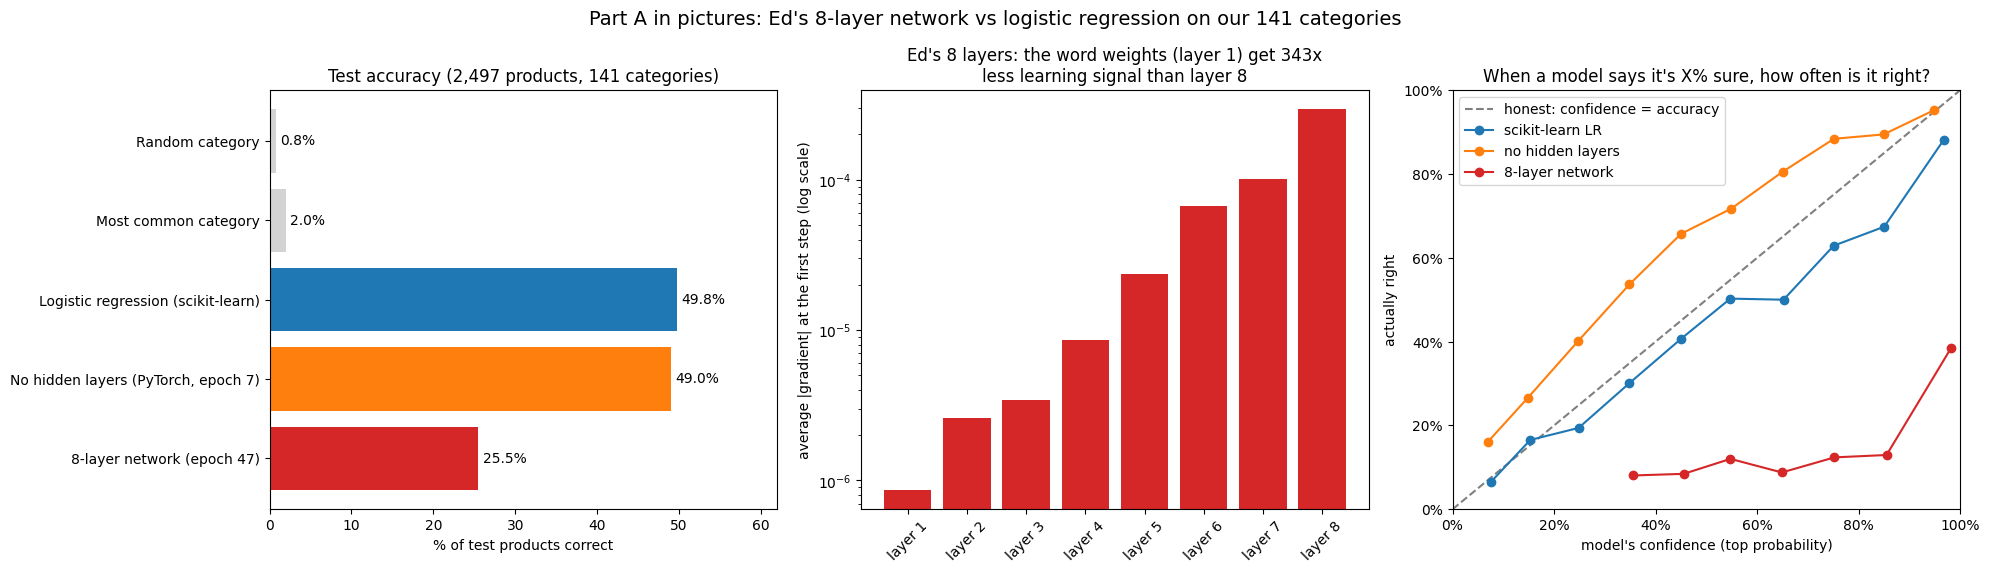

In [10]:
# Cell 9: Part A in pictures. Test accuracy, gradient strength per layer, and whether confidence is earned.
from matplotlib.ticker import PercentFormatter

# 1) Test accuracy for every model so far, plus Part 3's two know-nothing floors
rng = np.random.default_rng(42)
most_common = pd.Series(y_train).value_counts().idxmax()
acc = {"Random category": accuracy_score(y_test, rng.integers(0, N_CLASSES, len(y_test))),
       "Most common category": accuracy_score(y_test, np.full(len(y_test), most_common))}
acc.update({r["model"]: r["accuracy"] for r in results})

def color_for(name):
    if "Random" in name or "Most common" in name:
        return "lightgray"
    if "scikit-learn" in name:
        return "tab:blue"
    if "No hidden" in name:
        return "tab:orange"
    if "fixed" in name:
        return "tab:green"
    if "wide" in name:
        return "tab:purple"
    return "tab:red"                                      # the course's 8-layer network

# 2) Gradient strength per layer at the very first training step (a fresh 8-layer network, as in Step 4)
def first_step_gradients(net):
    """Average |gradient| of every linear layer's weights after one forward and backward pass on the first batch."""
    batch_X, batch_y = next(iter(make_loader()))
    net.train()
    net.zero_grad()
    loss_function(net(batch_X), batch_y).backward()
    return [m.weight.grad.abs().mean().item() for m in net.modules() if isinstance(m, nn.Linear)]

grads8 = first_step_gradients(build_model())

# 3) Calibration: group test predictions by confidence (0-10%, 10-20%, ...) and check how often each group is right
def calibration(P, min_products=20):
    conf, right = P.max(axis=1), P.argmax(axis=1) == y_test
    group = np.clip((conf * 10).astype(int), 0, 9)
    points = [(conf[group == g].mean(), right[group == g].mean())
              for g in range(10) if (group == g).sum() >= min_products]   # skip near-empty groups: too noisy
    return np.array(points).T

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

# Panel 1: test accuracy
ax = axes[0]
names = list(acc)
bars = ax.barh(names, [acc[n] * 100 for n in names], color=[color_for(n) for n in names])
ax.bar_label(bars, labels=[f"{acc[n]:.1%}" for n in names], padding=3)
ax.invert_yaxis()
ax.set(title="Test accuracy (2,497 products, 141 categories)", xlabel="% of test products correct",
       xlim=(0, max(62, max(acc.values()) * 100 + 12)))

# Panel 2: gradient per layer, log scale
ax = axes[1]
ax.bar([f"layer {i}" for i in range(1, len(grads8) + 1)], grads8, color="tab:red")
ax.set_yscale("log")
ax.set(title=f"The course's 8 layers: the word weights (layer 1) get {grads8[-1] / grads8[0]:.0f}x\nless learning signal than layer 8",
       ylabel="average |gradient| at the first step (log scale)")
ax.tick_params(axis="x", rotation=45)

# Panel 3: reliability diagram
ax = axes[2]
ax.plot([0, 100], [0, 100], "--", color="gray", label="honest: confidence = accuracy")
for name, color in [("scikit-learn LR", "tab:blue"), ("no hidden layers", "tab:orange"), ("8-layer network", "tab:red")]:
    conf, right = calibration(test_probs[name])
    ax.plot(conf * 100, right * 100, "o-", color=color, label=name)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set(title="When a model says it's X% sure, how often is it right?",
       xlabel="model's confidence (top probability)", ylabel="actually right", xlim=(0, 100), ylim=(0, 100))
ax.legend(loc="best")

fig.suptitle("Part A in pictures: the course's 8-layer network vs logistic regression on our 141 categories", fontsize=14)
plt.tight_layout()
plt.savefig("assets/part4_partA_results.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 9 findings

- **Test accuracy:** the two know-nothing floors (0.8% and 2.0%) match Part 3. The course's 8-layer network (25.5%) sits halfway between them and logistic regression (49.8%).
- **The vanishing gradient in one picture:** every layer back from the output gets less learning signal, and the word weights in layer 1 get **343x less** than layer 8. (Step 4 printed rounded numbers; this chart uses full precision.)
- **Calibration:**
  - **8-layer network: far below the diagonal.** Wherever its confidence sits between 35% and 85%, it's right only 8 to 13% of the time; at 98% confidence it's right 38% of the time. Its confidence carries almost no information.
  - **scikit-learn: close to the diagonal at low confidence, somewhat overconfident above 60%.** At about 97% confidence it's right 88% of the time.
  - **No hidden layers (PyTorch): above the diagonal everywhere**, so under-confident: at 35% confidence it's right 54% of the time. Stopping at epoch 7 left its scores small.

## Step 10: Improve the network, one fix per problem

**Why:** Part A found three problems with the course's network on our data. Each has a standard fix, and each fix is a building block of every transformer, including the LLM in Part B:

| Problem we measured | Fix |
|---|---|
| Vanishing gradient: layer 1 got about 340x less signal than layer 8 (Step 4) | **Skip connections** (each block computes x + f(x), so the gradient has a direct path back) and **LayerNorm** (keeps every layer's numbers at a steady scale) |
| The 64-number squeeze before choosing among 141 categories (Step 3) | **Wider layers:** 256 instead of 64 |
| Memorising: 95.8% right on training products, 27.5% on validation (Step 6) | **Dropout:** during training, randomly switch off 30 to 50% of the units, so no single memorised combination can carry an answer |

Two improved networks, same words and same training loop as before:

- **8 layers, fixed:** still 8 linear layers like the course's, with all three fixes.
- **1 wide hidden layer:** 512 units with dropout. The smallest step up from logistic regression: does one layer of word combinations add anything at all?

Each trains for 30 passes, keeps its best epoch on validation, and is scored once on the test set.

**What the code does:**

1. Defines the skip-connection block and the two networks.
2. Trains both with `train_model()` from Step 5, printing every 10th pass (about 1 to 2 minutes in total).
3. Scores both on the test set and lists every model so far.
4. Measures the learning signal per layer at the first step for the course's network and the fixed one.
5. Draws three panels (validation curves, learning signal per layer, test accuracy) and saves them to `assets/part4_improved_network.png`.

In [ ]:
# Cell 10: improve the network. One fix per problem found in Part A; same words, same training loop.
class ResidualBlock(nn.Module):
    """x + f(x): the block adds a correction to its input, so the gradient always has a direct path back."""
    def __init__(self, width, dropout):
        super().__init__()
        self.f = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, width), nn.ReLU(), nn.Dropout(dropout))

    def forward(self, x):
        return x + self.f(x)

class FixedDeepNetwork(nn.Module):
    """Still 8 linear layers like the course's, but wider (256), with skip connections, LayerNorm and dropout."""
    def __init__(self, input_size, n_classes, width=256, n_blocks=6, dropout=0.3):
        super().__init__()
        self.first = nn.Sequential(nn.Linear(input_size, width), nn.ReLU(), nn.Dropout(dropout))
        self.blocks = nn.Sequential(*[ResidualBlock(width, dropout) for _ in range(n_blocks)])
        self.last = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, n_classes))

    def forward(self, x):
        return self.last(self.blocks(self.first(x)))

class WideShallowNetwork(nn.Module):
    """One wide hidden layer (512) with dropout: the smallest step up from logistic regression."""
    def __init__(self, input_size, n_classes, width=512, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_size, width), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(width, n_classes))

    def forward(self, x):
        return self.net(x)

IMPROVED_EPOCHS = 30
NEW_NETWORKS = {"8 layers, fixed": FixedDeepNetwork, "1 wide hidden layer": WideShallowNetwork}
improved = {}   # name -> (network, history, best epoch, seconds)
for name, Network in NEW_NETWORKS.items():
    torch.manual_seed(42)
    net = Network(X_train_t.shape[1], N_CLASSES)
    start = time.time()
    hist, best = train_model(net, epochs=IMPROVED_EPOCHS, name=name, print_every=10)
    improved[name] = (net, hist, best, time.time() - start)
    n_params = sum(p.numel() for p in net.parameters())
    print(f"   {n_params:,} parameters | {IMPROVED_EPOCHS} passes in {improved[name][3]:.0f}s\n")

print("Test set (2,497 products):")
for name, (net, hist, best, secs) in improved.items():
    score(f"{name} (epoch {best})", predict(net, X_test_t), secs)
print("\nEvery model so far, best first:")
for r in sorted(results, key=lambda r: -r["accuracy"]):
    print(f"   {r['model']:40s} accuracy {r['accuracy']:6.1%} | macro-F1 {r['macro_f1']:.3f}")

# Gradient strength per layer at the first step: the course's network vs the fixed one (both fresh, same first batch)
torch.manual_seed(42)
grads_fixed = first_step_gradients(FixedDeepNetwork(X_train_t.shape[1], N_CLASSES))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

# Panel 1: validation accuracy per epoch, all four networks
ax = axes[0]
curves = [("course's 8 layers", hist8, "tab:red"), ("no hidden layers", hist0, "tab:orange")]
curves += [(name, improved[name][1], color) for name, color in [("8 layers, fixed", "tab:green"),
                                                                  ("1 wide hidden layer", "tab:purple")]]
for name, hist, color in curves:
    ax.plot(hist["epoch"], hist["val_acc"] * 100, "-", color=color, label=name)
ax.axhline(49.8, color="gray", linestyle="--", label="scikit-learn LR: 49.8% (test)")
ax.set(title="Validation accuracy per epoch", xlabel="epoch", ylabel="% of validation products correct")
ax.legend(loc="lower right")

# Panel 2: gradient flow, before and after the fix
ax = axes[1]
layers = np.arange(1, len(grads8) + 1)
ax.plot(layers, grads8, "o-", color="tab:red", label="course's 8 layers")
ax.plot(layers, grads_fixed, "o-", color="tab:green", label="8 layers, fixed (skip connections + LayerNorm)")
ax.set_yscale("log")
ax.set_xticks(layers)
ax.set(title=f"Learning signal per layer at the first step\nlayer 8 vs layer 1: {grads8[-1] / grads8[0]:.0f}x before, "
             f"{grads_fixed[-1] / grads_fixed[0]:.0f}x after the fix",
       xlabel="linear layer (1 = the word weights)", ylabel="average |gradient| (log scale)")
ax.legend()

# Panel 3: test accuracy, every model so far
ax = axes[2]
res = pd.DataFrame(results).sort_values("accuracy")
bars = ax.barh(res["model"], res["accuracy"] * 100, color=[color_for(n) for n in res["model"]])
ax.bar_label(bars, labels=[f"{a:.1%}" for a in res["accuracy"]], padding=3)
ax.set(title="Test accuracy (2,497 products)", xlabel="% of test products correct",
       xlim=(0, max(62, res["accuracy"].max() * 100 + 12)))

fig.suptitle("Step 10: one fix per problem. Does a better-built network beat logistic regression?", fontsize=14)
plt.tight_layout()
plt.savefig("assets/part4_improved_network.png", dpi=150, bbox_inches="tight")
plt.show()

8 layers, fixed:


8 layers, fixed: epoch 1/30:   0%|          | 0/313 [00:00<?, ?batch/s]

8 layers, fixed: epoch 2/30:   0%|          | 0/313 [00:00<?, ?batch/s]

8 layers, fixed: epoch 3/30:   0%|          | 0/313 [00:00<?, ?batch/s]

8 layers, fixed: epoch 4/30:   0%|          | 0/313 [00:00<?, ?batch/s]

...

1 wide hidden layer: epoch 12/30:   0%|          | 0/313 [00:00<?, ?batch/s]

1 wide hidden layer: epoch 13/30:   0%|          | 0/313 [00:00<?, ?batch/s]

1 wide hidden layer: epoch 14/30:   0%|          | 0/313 [00:00<?, ?batch/s]

1 wide hidden layer: epoch 15/30:   0%|          | 0/313 [00:00<?, ?batch/s]

1 wide hidden layer: epoch 16/30:   0%|          | 0/313 [00:00<?, ?batch/s]

### Step 10 findings

| Network (test set, 2,497 products) | Accuracy | Macro-F1 | Parameters | Best epoch (validation) |
|---|---|---|---|---|
| **1 wide hidden layer** (512 units, dropout 0.5) | **53.5%** | **0.444** | 1,096,845 | 4 (55.1%) |
| 8 layers, fixed (skip connections, LayerNorm, width 256, dropout 0.3) | 49.9% | 0.411 | 946,829 | 8 (51.0%) |
| Logistic regression (scikit-learn) | 49.8% | 0.418 | 282,141 | trained to convergence |
| No hidden layers (PyTorch) | 49.0% | 0.354 | 282,141 | 7 (51.8%) |
| The course's 8 layers | 25.5% | 0.180 | 294,349 | 47 (27.5%) |

- **The fixes worked.** Same depth, same words, same loop: the course's 8 layers went from 25.5% to 49.9% with skip connections, LayerNorm, wider layers and dropout. The learning signal is now almost flat across the layers: layer 8 gets 2x what layer 1 gets, down from 343x. These are the building blocks of every transformer layer.
- **One wide hidden layer is the first model in this project to beat logistic regression: 53.5% vs 49.8%** (+3.7 points). Macro-F1 rose too (0.444 vs 0.418), so the small categories gained, not just the big ones. It was also the fastest learner: about 46% on validation after one pass, best at epoch 4.
- **Depth still didn't pay, even fixed.** 8 fixed layers only matched logistic regression; one wide layer beat it. With 20,027 products, one layer of word combinations helps; more layers don't.
- **Every network still memorises:** about 99% right on training products by epoch 30, against 50 to 55% on validation. Dropout slows it down; keeping the best epoch on validation is what stops it.

## Part A summary: neural networks on our products

- **The course's 8-layer network: 25.5%** on the test set, against **49.8%** for logistic regression on the same words.
- **Why it failed, each cause measured:** the learning signal faded 343x on its way back to the word weights (Steps 4 and 9), the network memorised training products (Steps 5 and 6), and its confidence meant nothing (Steps 8 and 9).
- **Two ways back to 50%:** remove every hidden layer (49.0%), or keep 8 layers and fix them with skip connections, LayerNorm, width and dropout (49.9%).
- **One wide hidden layer with dropout beat logistic regression: 53.5%**, the best model in the project so far.
- **Why the same network won in the course:** it trained on 800,000 products to predict one price; we have 20,027 products and 141 categories. Price depends on word combinations ("16GB" next to "laptop" vs "USB stick"); a category mostly adds up word by word. Neural networks need data, and the architecture has to fit the problem.

# Part B: an LLM with no tuning

## Step 11: The prompt, and one product

**Why:** this is the "before" number for Day 5. gpt-4.1-nano gets no training on our data: it reads a product summary and the 141 category names and picks one, using only what it learned in pre-training (zero-shot). Day 5 fine-tunes this same model on our training products, so that comparison will be the same model before and after.

Three design choices:

- **Same input as Part A:** Part 2's `summary`, so the only difference from 49.8% is the model.
- **The answer can only be one of the 141 categories.** Structured outputs with a strict JSON schema whose `enum` lists the 141 names: while the model writes its answer, the API only allows tokens that keep it on one of those names (constrained decoding). It can't invent or misspell a category. Part 2's lesson again: a rule in a prompt is a request; a rule in code is a guarantee.
- **What's the same for every product goes first.** The instructions and the 141 names never change, so they lead the prompt and the product comes last. OpenAI caches a repeated prompt start of 1,024+ tokens and charges less for it.

We start with one product, the cosplay shoes. They're a training product, but nano has never trained on our data, so it's a fair check, and the validation and test products stay untouched while we build the prompt.

**What the code does:**

1. Loads the OpenAI key from the course's `.env`, as in Part 2 (never printed).
2. Builds the system prompt with the 141 category names, and the strict schema.
3. Sends the cosplay shoes twice (the second call should hit the cache) and prints nano's answer, the tokens used, how many were cached, and the cost.
4. Estimates the cost of all 2,497 test products three ways: normal calls with nothing cached, normal calls with the prompt start cached, and the Batch API.
5. Draws where the input tokens go and the three cost estimates, saved to `assets/part4_nano_prompt_cost.png`.


Calling gpt-4.1-nano:   0%|          | 0/2 [00:00<?, ?call/s]

call 1: 2,190 input tokens (0 cached), 10 output tokens, $0.000223
call 2: 2,190 input tokens (2,048 cached), 10 output tokens, $0.000069

System prompt: 5,066 characters listing 141 categories
Product:          Title: League of Legends Agony's Embrace Evelynn K/DA Skin Cosplay Shoes Lilac
nano's answer:    Apparel & Accessories > Shoes
Correct category: Apparel & Accessories > Costumes & Accessories  ->  WRONG

   normal calls, nothing cached               $0.56 for all 2,497 test products
   normal calls, prompt start cached          $0.17 for all 2,497 test products
   Batch API (half price, no cache assumed)   $0.28 for all 2,497 test products


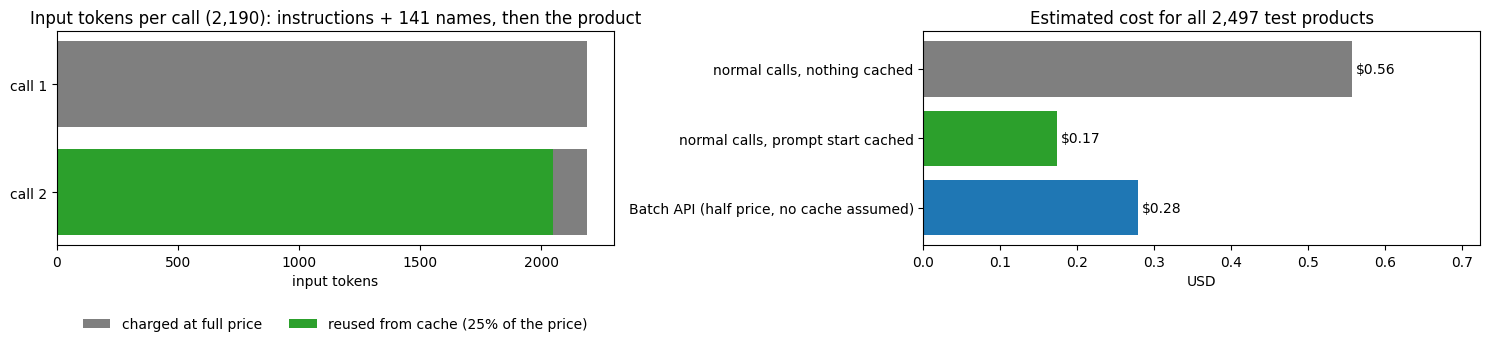

In [ ]:
# Cell 11: the untuned LLM. Prompt, strict schema, and one product (plus what caching saves).
import os
import json
from dotenv import load_dotenv
from openai import OpenAI

# Key lives in the course repo's .env, as in Part 2. Load it from there; never print it.
load_dotenv("/Users/raghvendaraokoduri/projects/llm_engineering/.env", override=True)
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in the .env file"
client = OpenAI()

LLM = "gpt-4.1-nano"                  # the model Day 5 will fine-tune
CATEGORIES = list(encoder.classes_)   # the 141 names, alphabetical (the same order as the ids)

# USD per million tokens for gpt-4.1-nano (check OpenAI's pricing page). The Batch API halves them.
PRICE_INPUT, PRICE_CACHED, PRICE_OUTPUT = 0.10, 0.025, 0.40

# 1) The system prompt: identical for every product, so it goes first (and can be cached)
SYSTEM_PROMPT = (
    "You categorise products for an online store.\n"
    "Read the product and choose the single best category from this list:\n\n"
    + "\n".join(CATEGORIES)
    + "\n\nAnswer with the category name exactly as written in the list."
)

# 2) The strict schema: the answer can only be one of the 141 names (constrained decoding)
RESPONSE_FORMAT = {
    "type": "json_schema",
    "json_schema": {
        "name": "product_category",
        "strict": True,
        "schema": {
            "type": "object",
            "properties": {"category": {"type": "string", "enum": CATEGORIES}},
            "required": ["category"],
            "additionalProperties": False,
        },
    },
}

def classify(summary: str):
    """Ask the untuned LLM for one product's category. Returns (category, usage)."""
    response = client.chat.completions.create(
        model=LLM,
        messages=[{"role": "system", "content": SYSTEM_PROMPT},
                  {"role": "user", "content": summary}],          # the product goes last
        response_format=RESPONSE_FORMAT,
        temperature=0,
        max_tokens=50,
    )
    return json.loads(response.choices[0].message.content)["category"], response.usage

def cached_tokens(usage):
    return (getattr(usage.prompt_tokens_details, "cached_tokens", 0) or 0) if usage.prompt_tokens_details else 0

def cost(usage, batch=False):
    """USD for one call. Normal calls get the cache discount; for the Batch API we assume none and halve the price."""
    cached = 0 if batch else cached_tokens(usage)
    dollars = ((usage.prompt_tokens - cached) * PRICE_INPUT + cached * PRICE_CACHED
               + usage.completion_tokens * PRICE_OUTPUT) / 1e6
    return dollars / 2 if batch else dollars

# 3) One product, the cosplay shoes, sent twice: the second call should reuse the cached prompt start
row = train.iloc[5]
calls = []
for attempt in tqdm(range(2), desc="Calling gpt-4.1-nano", unit="call"):
    answer, usage = classify(row["summary"])
    calls.append(usage)
    print(f"call {attempt + 1}: {usage.prompt_tokens:,} input tokens ({cached_tokens(usage):,} cached), "
          f"{usage.completion_tokens} output tokens, ${cost(usage):.6f}")

print(f"\nSystem prompt: {len(SYSTEM_PROMPT):,} characters listing {len(CATEGORIES)} categories")
print(f"Product:          {row['summary'].splitlines()[0]}")
print(f"nano's answer:    {answer}")
print(f"Correct category: {row['label']}  ->  {'right' if answer == row['label'] else 'WRONG'}")

# 4) What would all 2,497 test products cost?
per_product = {"normal calls, nothing cached": cost(calls[0]),
               "normal calls, prompt start cached": cost(calls[1]),
               "Batch API (half price, no cache assumed)": cost(calls[0], batch=True)}
print()
for how, usd in per_product.items():
    print(f"   {how:42s} ${usd * len(test):.2f} for all {len(test):,} test products")

# 5) Picture: where the input tokens go, and what caching saves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 3.8))
for i, u in enumerate(calls):
    c = cached_tokens(u)
    ax1.barh(f"call {i + 1}", c, color="tab:green", label="reused from cache (25% of the price)" if i == 1 else None)
    ax1.barh(f"call {i + 1}", u.prompt_tokens - c, left=c, color="tab:gray", label="charged at full price" if i == 0 else None)
ax1.invert_yaxis()
ax1.set(title=f"Input tokens per call ({calls[0].prompt_tokens:,}): instructions + 141 names, then the product",
        xlabel="input tokens")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, frameon=False)
totals = [usd * len(test) for usd in per_product.values()]
bars = ax2.barh(list(per_product), totals, color=["tab:gray", "tab:green", "tab:blue"])
ax2.bar_label(bars, labels=[f"${t:.2f}" for t in totals], padding=3)
ax2.invert_yaxis()
ax2.set(title=f"Estimated cost for all {len(test):,} test products", xlabel="USD", xlim=(0, max(totals) * 1.3))
plt.tight_layout()
plt.savefig("assets/part4_nano_prompt_cost.png", dpi=150, bbox_inches="tight")
plt.show()


### Step 11 findings

- **nano filed the cosplay shoes under Apparel & Accessories > Shoes.** The dataset says Costumes & Accessories. The words say "shoes"; the convention says costume. Our trained models had learned that convention from examples (Step 8).
- **Every call sends 2,190 input tokens**, almost all of them the instructions and the 141 category names. On the second call, 2,048 of them came from the cache: $0.000223 → $0.000069 per product, 69% cheaper.
- **Caching beat the Batch API here:** about $0.17 for all 2,497 test products with normal calls and a cached prompt start, against about $0.28 at Batch prices without caching ($0.56 with neither). So Part B uses normal parallel calls, with no 24-hour wait.

## Step 12: 100 validation products, next to our best trained models

**Why:** one product is an anecdote. 100 validation products give a first real number before we touch the test set, and they're the products we're allowed to read closely while the prompt can still change. With 100 products the noise is about ±10 points, so this is a direction check, not a result.

Accuracy alone hides *how* nano is wrong. Every category has an aisle (the part before " > ", like Apparel & Accessories) and a shelf (like Costumes & Accessories). Each answer lands in one of three places:

- **Right.**
- **Right aisle, wrong shelf:** it understood the product but picked a neighbouring category, like Shoes for the cosplay shoes. That's a convention problem, the kind fine-tuning should fix.
- **Wrong aisle:** it misread the product, or the label itself is debatable.

**What the code does:**

1. Picks 100 validation products (fixed seed) and sends them to nano, 8 at a time, with a progress bar. Answers are saved to `data/part4_nano_validation100.json`, so re-running the cell never pays twice. Cost: about 1 cent.
2. Runs our two best trained models (1 wide hidden layer, logistic regression) on the same 100 products.
3. Splits each model's answers into right / right aisle, wrong shelf / wrong aisle and draws them (`assets/part4_nano_validation100.png`).
4. Lists nano's first 10 mistakes, to read.

gpt-4.1-nano on 100 validation products:   0%|          | 0/100 [00:00<?, ?product/s]

These 100 calls cost $0.0086: about $0.21 for all 2,497 test products

On the same 100 validation products (±10 points of noise at this size):
                              right right aisle, wrong shelf wrong aisle
gpt-4.1-nano, untuned           38%                      15%         47%
1 wide hidden layer (trained)   52%                      10%         38%
logistic regression (trained)   49%                      13%         38%


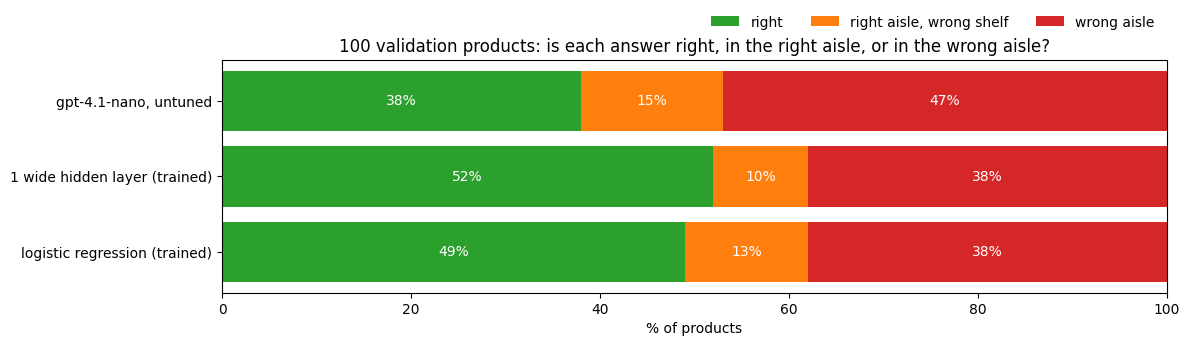


nano's first 10 mistakes:
 1. Title: Atlantis [LP]
    correct: Services > Entertainment & Recreation Services
    nano:    Media > Videos  (WRONG AISLE)
 2. Title: Paterson Major Focus Finder
    correct: Cameras & Optics > Photography
    nano:    Arts & Entertainment > Hobbies & Creative Arts  (WRONG AISLE)
 3. Title: Stainless Steel Thimbles 10mm
    correct: Hardware > Hardware Accessories
    nano:    Arts & Entertainment > Hobbies & Creative Arts  (WRONG AISLE)
 4. Title: Ron White Pricilla
    correct: Apparel & Accessories > Shoes
    nano:    Arts & Entertainment > Hobbies & Creative Arts  (WRONG AISLE)
 5. Title: Shinery Radiance Duo Jewelry Cleaning Kit
    correct: Health & Beauty > Jewelry Cleaning & Care
    nano:    Apparel & Accessories > Jewelry  (WRONG AISLE)
 6. Title: Wisconsin River Falls Stadium Seat
    correct: Sporting Goods > Athletics
    nano:    Arts & Entertainment > Party & Celebration  (WRONG AISLE)
 7. Title: Sandstone Corner Post 5" x 5" x 8' for Vin

In [ ]:
# Cell 12: 100 validation products through the untuned LLM, next to our two best trained models
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

N_DEV = 100
dev = val.sample(N_DEV, random_state=42)                 # the same 100 products every run
dev_pos = val.index.get_indexer(dev.index)               # their row positions, to pick the same rows from X_val
NANO_DEV_FILE = Path("data/part4_nano_validation100.json")

def classify_many(summaries, workers=8, desc="gpt-4.1-nano"):
    """Classify many products in parallel. Returns (answers, usages) in input order; failed calls stay None."""
    answers, usages = [None] * len(summaries), [None] * len(summaries)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = {pool.submit(classify, s): i for i, s in enumerate(summaries)}
        for f in tqdm(as_completed(futures), total=len(futures), desc=desc, unit="product"):
            i = futures[f]
            try:
                answers[i], usages[i] = f.result()
            except Exception as e:
                print(f"   call {i} failed: {e}")
    return answers, usages

# 1) Ask nano, once: answers are saved, so re-running this cell never pays twice
if NANO_DEV_FILE.exists():
    saved = json.loads(NANO_DEV_FILE.read_text())
    dev_answers, dev_cost = saved["answers"], saved["cost_usd"]
    print(f"Loaded {len(dev_answers)} saved answers from {NANO_DEV_FILE} (no new API calls)")
else:
    dev_answers, dev_usages = classify_many(dev["summary"].tolist(), desc=f"gpt-4.1-nano on {N_DEV} validation products")
    dev_cost = sum(cost(u) for u in dev_usages if u is not None)
    NANO_DEV_FILE.write_text(json.dumps({"answers": dev_answers, "cost_usd": dev_cost}))
print(f"These {N_DEV} calls cost ${dev_cost:.4f}: about ${dev_cost / N_DEV * len(test):.2f} for all {len(test):,} test products")

# 2) Our two best trained models on the same 100 products
wide_net = improved["1 wide hidden layer"][0]
truth = dev["label"].tolist()
answers_by_model = {
    "gpt-4.1-nano, untuned": dev_answers,
    "1 wide hidden layer (trained)": list(encoder.classes_[predict(wide_net, X_val_t[torch.as_tensor(dev_pos)])]),
    "logistic regression (trained)": list(encoder.classes_[sk_lr.predict(X_val[dev_pos])]),
}

def breakdown(answers, truth):
    """Share right, right aisle but wrong shelf (same top-level category), and wrong aisle."""
    aisle = lambda c: c.split(" > ")[0] if c else None
    right = np.array([a == t for a, t in zip(answers, truth)])
    same_aisle = np.array([aisle(a) == aisle(t) for a, t in zip(answers, truth)])
    return {"right": right.mean(), "right aisle, wrong shelf": (same_aisle & ~right).mean(),
            "wrong aisle": (~same_aisle).mean()}

table = pd.DataFrame({name: breakdown(ans, truth) for name, ans in answers_by_model.items()}).T
print("\nOn the same 100 validation products (±10 points of noise at this size):")
print(table.apply(lambda col: col.map("{:.0%}".format)).to_string())

# 3) Picture: right, right aisle but wrong shelf, wrong aisle
fig, ax = plt.subplots(figsize=(12, 3.6))
left = np.zeros(len(table))
for part, color in [("right", "tab:green"), ("right aisle, wrong shelf", "tab:orange"), ("wrong aisle", "tab:red")]:
    values = table[part].to_numpy() * 100
    bars = ax.barh(table.index, values, left=left, color=color, label=part)
    ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 4 else "" for v in values], label_type="center", color="white")
    left += values
ax.invert_yaxis()
ax.set(title=f"{N_DEV} validation products: is each answer right, in the right aisle, or in the wrong aisle?",
       xlabel="% of products", xlim=(0, 100))
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.08), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("assets/part4_nano_validation100.png", dpi=150, bbox_inches="tight")
plt.show()

# 4) Read nano's mistakes: knowledge or convention?
print("\nnano's first 10 mistakes:")
shown = 0
for i, (a, t) in enumerate(zip(dev_answers, truth)):
    if a != t and shown < 10:
        shown += 1
        aisle_note = "right aisle" if a and a.split(" > ")[0] == t.split(" > ")[0] else "WRONG AISLE"
        print(f"{shown:2d}. {dev['summary'].iloc[i].splitlines()[0]}")
        print(f"    correct: {t}\n    nano:    {a}  ({aisle_note})")

### Step 12 findings

| Same 100 validation products | Right | Right aisle, wrong shelf | Wrong aisle |
|---|---|---|---|
| gpt-4.1-nano, untuned | 38% | 15% | 47% |
| 1 wide hidden layer (trained) | 52% | 10% | 38% |
| Logistic regression (trained) | 49% | 13% | 38% |

- **Untuned nano is 11 to 14 points behind our trained models** on these 100 products. That's within sight of the ±10 points of noise at this size, so it's a direction, not a verdict. The 100 calls cost $0.0086.
- **Most of nano's misses are in the wrong aisle (47%).** Some are knowledge gaps: a Paterson Major Focus Finder, a darkroom tool, went to Hobbies & Creative Arts instead of Photography. Some are this dataset's conventions: a Polaroid camera went to Electronics > Video instead of Cameras & Optics, a jewelry cleaning kit to Jewelry instead of Health & Beauty.
- **nano has a favourite catch-all:** Arts & Entertainment > Hobbies & Creative Arts, for steel thimbles, a focus finder and a pair of Ron White shoes.

## Step 13: Other untuned LLMs, through OpenRouter

**Why:** nano is the model Day 5 will fine-tune, but is its score a nano problem or an "untuned LLM" problem? Bigger models from other labs answer that. They go through OpenRouter (one key, OpenAI-compatible client), with exactly nano's prompt, the same 141-name schema and the same 100 validation products. If a model doesn't support the strict schema, it's asked for plain text, and any answer that isn't one of the 141 names counts as wrong.

**What the code does:**

1. Checks every id in `OTHER_MODELS` against OpenRouter's model list (missing ids are skipped and print similar ids) and reads each model's real price.
2. Sends the 100 products to each model, 8 at a time; answers are saved to `data/part4_openrouter_validation100.json`, so re-running never pays twice.
3. Prints right / right aisle, wrong shelf per model, with the projected cost for all 2,497 test products.
4. Draws every model, trained and untuned, on one chart (`assets/part4_llms_validation100.png`).

anthropic/claude-sonnet-4.5:   0%|          | 0/100 [00:00<?, ?product/s]

google/gemini-2.5-flash:   0%|          | 0/100 [00:00<?, ?product/s]

openai/gpt-5-mini:   0%|          | 0/100 [00:00<?, ?product/s]


On the same 100 validation products (±10 points of noise):
   google/gemini-2.5-flash, untuned           right  73% | right aisle, wrong shelf  13% | $1.53 for all 2,497 test products
   openai/gpt-5-mini, untuned                 right  68% | right aisle, wrong shelf  13% | $2.20 for all 2,497 test products
   1 wide hidden layer (trained)              right  52% | right aisle, wrong shelf  10%
   logistic regression (trained)              right  49% | right aisle, wrong shelf  13%
   anthropic/claude-sonnet-4.5, untuned       right  45% | right aisle, wrong shelf  42% | $24.72 for all 2,497 test products
   gpt-4.1-nano, untuned                      right  38% | right aisle, wrong shelf  15% | $0.21 for all 2,497 test products


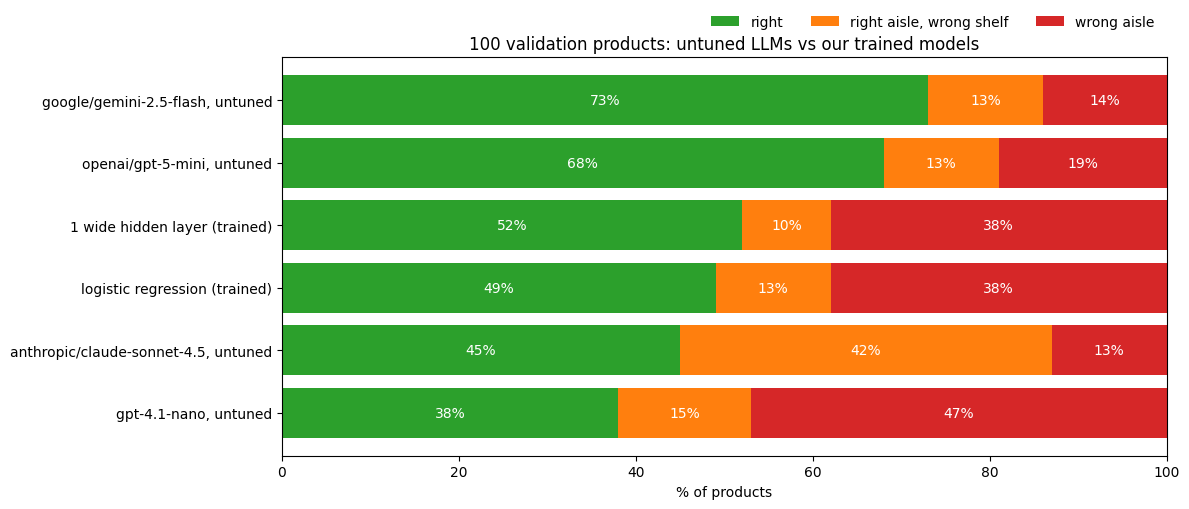

In [ ]:
# Cell 13: other untuned LLMs through OpenRouter, on the same 100 validation products
import urllib.request

# Edit this list freely: any model id from https://openrouter.ai/models (missing ids are skipped, not billed)
OTHER_MODELS = ["anthropic/claude-sonnet-4.5", "google/gemini-2.5-flash", "openai/gpt-5-mini"]

assert os.getenv("OPENROUTER_API_KEY"), "OPENROUTER_API_KEY not found in the .env file"
router = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"))

# 1) Check the ids exist and read their real prices (USD per token) from OpenRouter's model list
with urllib.request.urlopen("https://openrouter.ai/api/v1/models") as r:
    catalog = {m["id"]: m for m in json.load(r)["data"]}
models = [m for m in OTHER_MODELS if m in catalog]
for m in OTHER_MODELS:
    if m not in catalog:
        close = [k for k in catalog if m.split("/")[-1].split("-")[0] in k][:5]
        print(f"Skipping {m}: not on OpenRouter. Similar ids: {close}")
price = {m: (float(catalog[m]["pricing"]["prompt"]), float(catalog[m]["pricing"]["completion"])) for m in models}

def classify_with(model, summary):
    """Same prompt and strict schema as nano. If a model rejects the schema, ask for plain text and match it."""
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": summary}]
    try:
        r = router.chat.completions.create(model=model, messages=messages, response_format=RESPONSE_FORMAT,
                                           temperature=0, max_tokens=1000)
        text = r.choices[0].message.content or ""
        answer = json.loads(text[text.find("{"):text.rfind("}") + 1])["category"]
    except Exception:
        r = router.chat.completions.create(model=model, messages=messages, temperature=0, max_tokens=1000)
        answer = (r.choices[0].message.content or "").strip().strip('"')
    if answer not in CATEGORIES:
        answer = None                                         # an invented category counts as wrong
    u = r.usage
    usd = (u.prompt_tokens * price[model][0] + u.completion_tokens * price[model][1]) if u else 0.0
    return answer, usd

# 2) Ask each model once; answers are saved, so re-running never pays twice
OTHER_FILE = Path("data/part4_openrouter_validation100.json")
saved = json.loads(OTHER_FILE.read_text()) if OTHER_FILE.exists() else {}
summaries = dev["summary"].tolist()
for m in models:
    if m in saved:
        print(f"{m}: loaded saved answers (no new calls)")
        continue
    answers, costs = [None] * len(summaries), [0.0] * len(summaries)
    with ThreadPoolExecutor(max_workers=8) as pool:
        futures = {pool.submit(classify_with, m, s): i for i, s in enumerate(summaries)}
        for f in tqdm(as_completed(futures), total=len(futures), desc=m, unit="product"):
            i = futures[f]
            try:
                answers[i], costs[i] = f.result()
            except Exception as e:
                print(f"   {m}, call {i} failed: {e}")
    saved[m] = {"answers": answers, "cost_usd": sum(costs)}
    OTHER_FILE.write_text(json.dumps(saved))

# 3) Everyone on the same 100 products
for m in models:
    answers_by_model[f"{m}, untuned"] = saved[m]["answers"]
table = pd.DataFrame({name: breakdown(ans, truth) for name, ans in answers_by_model.items()}).T.sort_values("right")
costs_100 = {"gpt-4.1-nano, untuned": dev_cost, **{f"{m}, untuned": saved[m]["cost_usd"] for m in models}}
print("\nOn the same 100 validation products (±10 points of noise):")
for name, row in table[::-1].iterrows():
    extra = f" | ${costs_100[name] / N_DEV * len(test):.2f} for all {len(test):,} test products" if name in costs_100 else ""
    print(f"   {name:42s} right {row['right']:4.0%} | right aisle, wrong shelf {row['right aisle, wrong shelf']:4.0%}{extra}")

# 4) Picture: right / right aisle, wrong shelf / wrong aisle, for every model
fig, ax = plt.subplots(figsize=(12, 0.6 * len(table) + 1.6))
left = np.zeros(len(table))
for part, color in [("right", "tab:green"), ("right aisle, wrong shelf", "tab:orange"), ("wrong aisle", "tab:red")]:
    values = table[part].to_numpy() * 100
    bars = ax.barh(table.index, values, left=left, color=color, label=part)
    ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 4 else "" for v in values], label_type="center", color="white")
    left += values
ax.set(title=f"{N_DEV} validation products: untuned LLMs vs our trained models", xlabel="% of products", xlim=(0, 100))
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.04), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("assets/part4_llms_validation100.png", dpi=150, bbox_inches="tight")
plt.show()

### Step 13 findings

| Same 100 validation products | Right | Right aisle, wrong shelf | Wrong aisle | Cost for all 2,497 test products |
|---|---|---|---|---|
| Gemini 2.5 Flash, untuned | **73%** | 13% | 14% | $1.53 |
| GPT-5 mini, untuned | 68% | 13% | 19% | $2.20 |
| 1 wide hidden layer (trained) | 52% | 10% | 38% | |
| Logistic regression (trained) | 49% | 13% | 38% | |
| Claude Sonnet 4.5, untuned | 45% | 42% | 13% | $24.72 |
| gpt-4.1-nano, untuned | 38% | 15% | 47% | $0.21 |

- **nano's loss was a nano problem, not an LLM problem.** Gemini 2.5 Flash and GPT-5 mini beat our best trained model by 16 to 21 points without a single training example.
- **Their mistakes are different:** only 14 to 19% land in the wrong aisle, against 38% for the bag-of-words models. Big LLMs understand what the product is; they miss on this dataset's shelf conventions.
- **Claude Sonnet 4.5 needs a second look before any verdict.** It returned a valid category every time, yet 42% were right aisle, wrong shelf: three times anyone else. The likely suspect is the strict schema forcing its answer token by token, not its understanding. A run without the schema would tell.
- **Day 5's target:** fine-tuning has to take nano from 38% towards Gemini Flash's 73%.

## Step 14: The final chart

**Why:** one picture anyone can read, like the course's results chart: every model from Parts 3 and 4, one bar each, longest bar wins. Colours group the model families (know-nothing baselines, classic ML, neural networks, LLMs with no training), and the dashed line is the bar to beat, logistic regression's 49.8%.

Trained models are scored on all 2,497 test products. The untuned LLMs (striped, marked *) are so far measured on 100 validation products only, about ±10 points; their test-set run replaces those bars when it's done.

**What the code does:** collects every score already in this notebook (nothing is retrained or re-called) and saves the chart to `assets/part4_final_results.png` at high resolution for the README and the post.

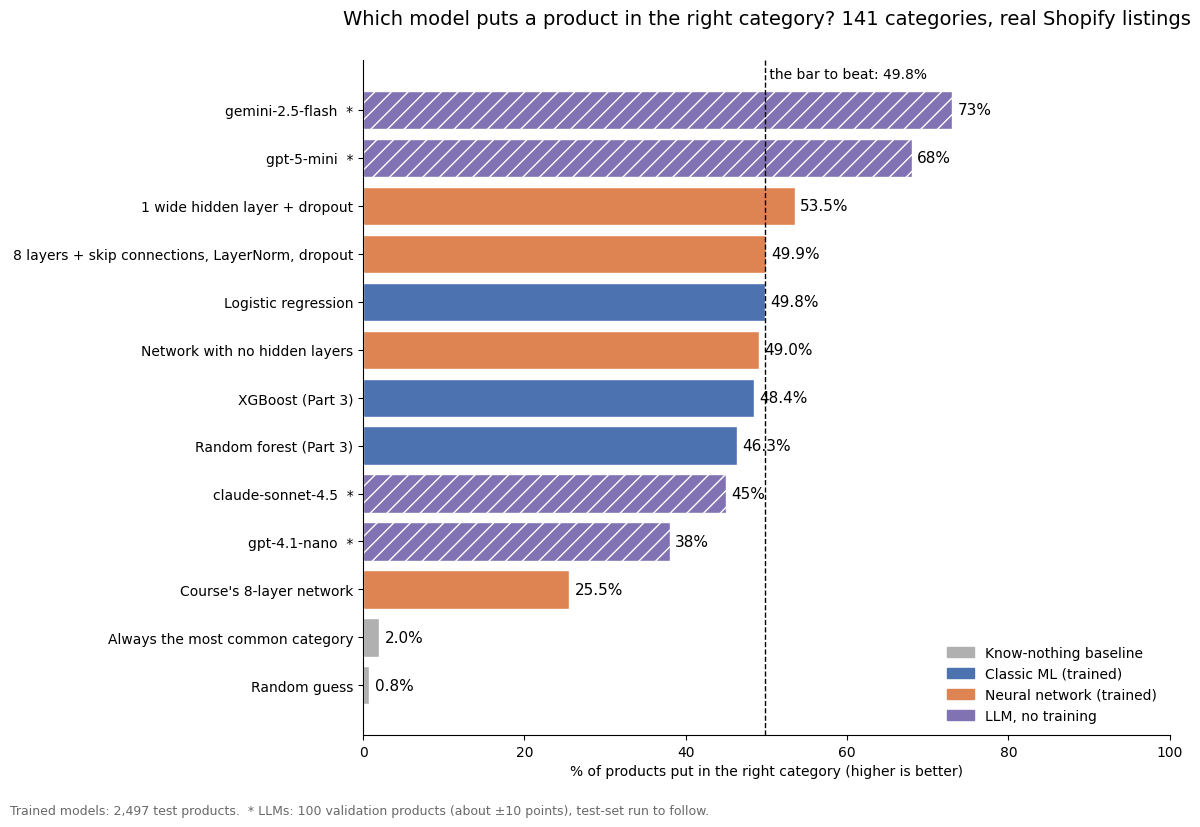

In [ ]:
# Cell 14: the final chart. Every model in Part 3 and Part 4 on one picture, like the course's results chart.
from matplotlib.patches import Patch

GROUPS = {"Know-nothing baseline": "#b0b0b0", "Classic ML (trained)": "#4c72b0",
          "Neural network (trained)": "#dd8452", "LLM, no training": "#8172b3"}

rows = [  # (label, % correct, group, measured on the full test set?)
    ("Random guess", acc["Random category"] * 100, "Know-nothing baseline", True),
    ("Always the most common category", acc["Most common category"] * 100, "Know-nothing baseline", True),
    ("Random forest (Part 3)", 46.3, "Classic ML (trained)", True),
    ("XGBoost (Part 3)", 48.4, "Classic ML (trained)", True),
]
nice = {"Logistic regression (scikit-learn)": ("Logistic regression", "Classic ML (trained)"),
        "8-layer network": ("Course's 8-layer network", "Neural network (trained)"),
        "No hidden layers": ("Network with no hidden layers", "Neural network (trained)"),
        "8 layers, fixed": ("8 layers + skip connections, LayerNorm, dropout", "Neural network (trained)"),
        "1 wide hidden layer": ("1 wide hidden layer + dropout", "Neural network (trained)")}
for r in results:
    for key, (label, group) in nice.items():
        if r["model"].startswith(key):
            rows.append((label, r["accuracy"] * 100, group, True))
for name in table.index:                                   # untuned LLMs, from Steps 12 and 13
    if "untuned" in name:
        rows.append((name.replace(", untuned", "").split("/")[-1], table.loc[name, "right"] * 100, "LLM, no training", False))

rows.sort(key=lambda r: r[1])
fig, ax = plt.subplots(figsize=(12, 0.48 * len(rows) + 2))
labels = [r[0] + ("" if r[3] else "  *") for r in rows]
bars = ax.barh(labels, [r[1] for r in rows], color=[GROUPS[r[2]] for r in rows],
               hatch=["" if r[3] else "//" for r in rows], edgecolor="white")
ax.bar_label(bars, labels=[f"{r[1]:.1f}%" if r[3] else f"{r[1]:.0f}%" for r in rows], padding=4, fontsize=11)
ax.axvline(49.8, color="black", linestyle="--", linewidth=1)
ax.text(49.8, len(rows) - 0.4, " the bar to beat: 49.8%", va="bottom", fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel("% of products put in the right category (higher is better)")
ax.set_title("Which model puts a product in the right category? 141 categories, real Shopify listings", fontsize=14, pad=26)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUPS.items()], loc="lower right", frameon=False)
fig.text(0.01, 0.005, "Trained models: 2,497 test products.  * LLMs: 100 validation products (about ±10 points), "
         "test-set run to follow.", fontsize=9, color="dimgray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("assets/part4_final_results.png", dpi=200, bbox_inches="tight")
plt.show()

## Findings

**Part A, neural networks (test set, 2,497 products):** the course's 8-layer network scored 25.5% against logistic regression's 49.8%. Deleting its hidden layers nearly doubled it (49.0%), fixing it with skip connections, LayerNorm and dropout matched the bar (49.9%), and one wide hidden layer with dropout beat it (53.5%). On 20,027 products the simple designs won; the course's network had 800,000 products and a single number to predict.

**Part B, LLMs with no training (100 validation products):** Gemini 2.5 Flash (73%) and GPT-5 mini (68%) beat every trained model; gpt-4.1-nano (38%) didn't beat logistic regression. Many of nano's misses are this catalogue's conventions, which is exactly what Day 5's fine-tuning should teach.

**Still to do:** the untuned LLMs on all 2,497 test products, and a check of Claude Sonnet 4.5 without the strict schema.